**SAPIANS** · SCC5819 · MÓDULO 00 — A BASE SRAG · DIAGNÓSTICO POR PERMUTAÇÃO

# O que acontece com o erro quando embaralhamos uma entrada?

O caderno de balanceamento preservou o modelo atual como referência probabilística.
Agora mantemos esse preditor fixo e comparamos seu erro original com o erro depois
de permutar separadamente cada entrada, acompanhando também a variação do ranking.

[README do módulo](../README.md) · [modelo do curso](srag_model_walkthrough.ipynb) ·
[núcleo reproduzível](../../../tools/srag_62_pfi.py) · [registro](../gold/pfi_ranking.json)

---

**Objetivos.** Separar erro original, erro perturbado e PFI; mostrar média e desvio
padrão das permutações; distinguir essa dispersão de incerteza populacional;
conferir como as posições mudam entre sorteios.

In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import contextlib
import io
import json
import os
import pathlib
import sys
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = pathlib.Path(os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())).resolve()
while REPO != REPO.parent and not (REPO / "tools/srag_62_pfi.py").exists():
    REPO = REPO.parent
if not (REPO / "tools/srag_62_pfi.py").exists():
    raise RuntimeError("Abra o caderno no repositório ou configure INTERPRETABLE_ML_REPO.")
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_62_pfi as P

WORK = pathlib.Path(tempfile.mkdtemp(prefix="srag-pfi-"))
os.chdir(WORK)
SP.aplicar()
RANDOM_STATE = 42
RUN_REFIT = False
E = json.loads((REPO / "modules/00-dataset/gold/pfi_ranking.json").read_text())
if RUN_REFIT:
    with contextlib.redirect_stdout(io.StringIO()):
        E = P.study(WORK / "refit", repeats=E["protocol"]["repeats"], seed=RANDOM_STATE)
print("Fonte: registro do experimento; a execução padrão não refaz o ajuste.")
print("Python:", sys.version.split()[0])

Fonte: registro do experimento; a execução padrão não refaz o ajuste.
Python: 3.12.13


## §1 — Modelo, pacientes, métrica e sorteios

O modelo atual não recebe pesos nem reamostragem. O ajuste usa o treino temporal
do curso; o diagnóstico usa o teste histórico inteiro. Esse teste já foi observado,
portanto esta análise é exploratória. A PFI não escolhe um novo modelo.

Cada repetição permuta uma coluna por vez. A mesma ordem de linhas é reutilizada
entre as perturbações separadas daquela repetição. Modelos, rótulos e conjunto de
pacientes permanecem fixos. Não há nova amostra de pacientes em cada sorteio.

In [3]:
protocol = E["protocol"]
for label, key in [("Ano de avaliação", "period"), ("Treino", "n_train"),
                   ("Registros avaliados", "n_evaluation"), ("Óbitos", "events"),
                   ("Repetições por coluna", "repeats"), ("Semente das permutações", "permutation_seed")]:
    print(label + ":", SP.pt_int(protocol[key]))
print("Entradas:", SP.pt_int(len(protocol["features"])))
print("Posições exibidas:", SP.pt_int(10))
print("SD amostral: ddof =", SP.pt_int(1))
print("Caixa: Q1–Q3; linha central: mediana; bigodes: até", SP.pt(1.5, 1), "IQR.")
print("Semente do modelo:", SP.pt_int(protocol["xgb_params"]["random_state"]))
print("Configuração:", json.dumps(protocol["xgb_params"], ensure_ascii=False))
print("Versões:", json.dumps(protocol["versions"], ensure_ascii=False))
print("SHA da amostra:", protocol["sample_sha256"])
print("SHA das ordens de permutação:", protocol["permutation_orders_sha256"])
for metric, value in E["original"].items():
    print("Referência " + metric + ":", SP.pt(value, 8))

Ano de avaliação: 2.024
Treino: 200.000
Registros avaliados: 16.142
Óbitos: 2.945
Repetições por coluna: 50
Semente das permutações: 42
Entradas: 40
Posições exibidas: 10
SD amostral: ddof = 1
Caixa: Q1–Q3; linha central: mediana; bigodes: até 1,5 IQR.
Semente do modelo: 42
Configuração: {"n_estimators": 800, "max_depth": 4, "learning_rate": 0.05, "min_child_weight": 100, "reg_lambda": 5.0, "tree_method": "hist", "enable_categorical": true, "eval_metric": "auc", "random_state": 42, "n_jobs": -1}
Versões: {"numpy": "2.4.6", "pandas": "2.3.3", "scikit-learn": "1.9.0", "xgboost": "3.4.1"}
SHA da amostra: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
SHA das ordens de permutação: 93f4064c96d8b86e6ed1eb5a3a5d486b9894223de180e609bdaf008dcddd651d
Referência brier: 0,13080778
Referência logloss: 0,40901958
Referência auc: 0,76444839


**O que olhar.** A referência pertence ao conjunto inteiro, não a uma variável.
Sua repetição nas linhas do gráfico serve para comparar as perturbações.

## §2 — Antes, depois e aumento do erro

Para Brier e log-loss, PFI é erro após permutar menos erro original. Para AUC,
invertemos a diferença: AUC original menos AUC após permutar. Nos dois casos,
valor positivo indica piora do desempenho. O ranking principal usa a média do
aumento do Brier entre todas as entradas; a seleção das maiores é descritiva.

O desvio padrão usa os sorteios da permutação. Como a referência original é
constante nessas repetições, o SD do erro após permutar é igual ao SD da PFI.
O SD da referência repetida é nulo por construção; isso não significa ausência
de incerteza sobre a população ou sobre o procedimento de treinamento.

In [4]:
rows = sorted(E["rows"], key=lambda row: row["metrics"]["brier"]["rank"])
table = pd.DataFrame([{
    "posição": r["metrics"]["brier"]["rank"], "variável": r["feature"],
    "Brier antes": E["original"]["brier"], "SD antes entre sorteios": 0.0,
    "Brier depois médio": r["metrics"]["brier"]["after_mean"],
    "SD depois": r["metrics"]["brier"]["after_sd"],
    "PFI média": r["metrics"]["brier"]["mean"],
    "SD da PFI": r["metrics"]["brier"]["sd"],
    "erro Monte Carlo da média": r["metrics"]["brier"]["mcse"],
} for r in rows])
print(SP.tabela(table, casas=8))
print()
print("Desvio da referência repetida:", SP.pt(0.0, 8), "por construção.")
for metric in ["logloss", "auc"]:
    secondary = pd.DataFrame([{"variável": r["feature"], "PFI média": r["metrics"][metric]["mean"],
        "SD": r["metrics"][metric]["sd"], "posição": r["metrics"][metric]["rank"]} for r in rows])
    print()
    print("Métrica secundária:", metric)
    print(SP.tabela(secondary, casas=8))

posição                 variável Brier antes SD antes entre sorteios Brier depois médio  SD depois   PFI média  SD da PFI erro Monte Carlo da média
      1               idade_anos  0,13080778              0,00000000         0,15425722 0,00073672  0,02344944 0,00073672                0,00010419
      2                saturacao  0,13080778              0,00000000         0,13509785 0,00032827  0,00429007 0,00032827                0,00004642
      3                desc_resp  0,13080778              0,00000000         0,13361822 0,00023345  0,00281044 0,00023345                0,00003302
      4               cs_escol_n  0,13080778              0,00000000         0,13320743 0,00022399  0,00239965 0,00022399                0,00003168
      5                 dispneia  0,13080778              0,00000000         0,13309244 0,00018807  0,00228466 0,00018807                0,00002660
      6                 puerpera  0,13080778              0,00000000         0,13293205 0,00011376  0,00212427 0

**O que olhar.** O aumento do erro tem a mesma unidade do Brier, e não representa
diretamente uma porcentagem de classificações erradas. SD descreve dispersão;
o erro de Monte Carlo descreve a precisão da média desses sorteios, condicionado
ao modelo e aos pacientes presentes.

## §3 — Figuras do antes/depois e da distribuição

No primeiro painel, o quadrado é o erro original e o círculo é o erro médio após
permutar; a haste azul indica um desvio padrão para cada lado. No painel de PFI,
caixas e pontos mostram a distribuição, com média e SD sobrepostos. Os bigodes
da caixa não são SD nem intervalo de confiança. A ampliação seguinte omite apenas
a primeira posição e mantém escala comum entre as demais linhas.

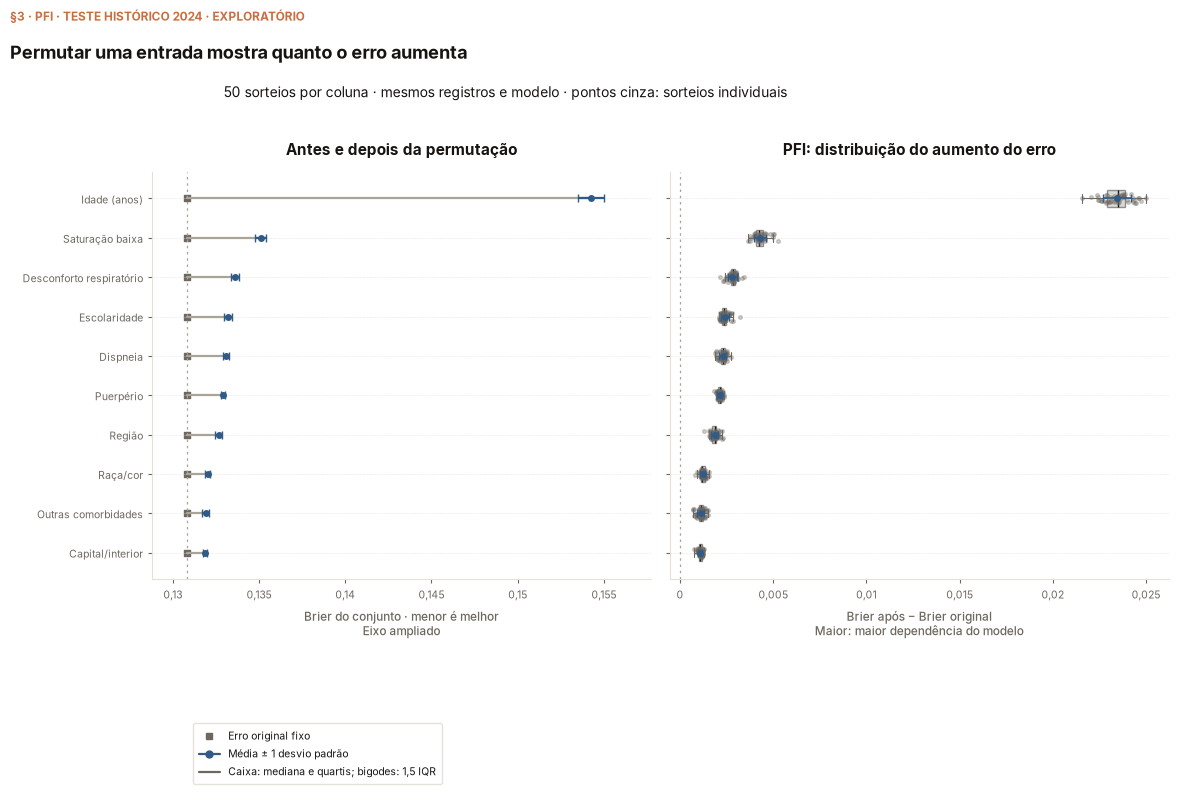

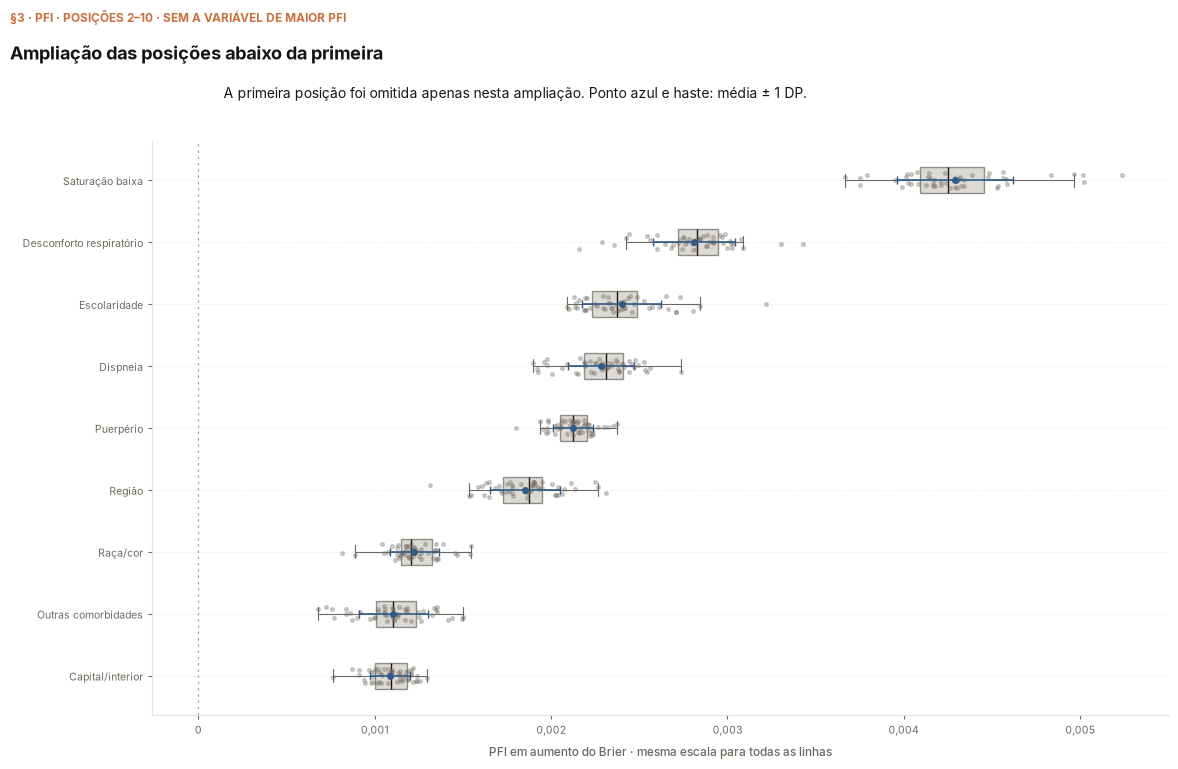

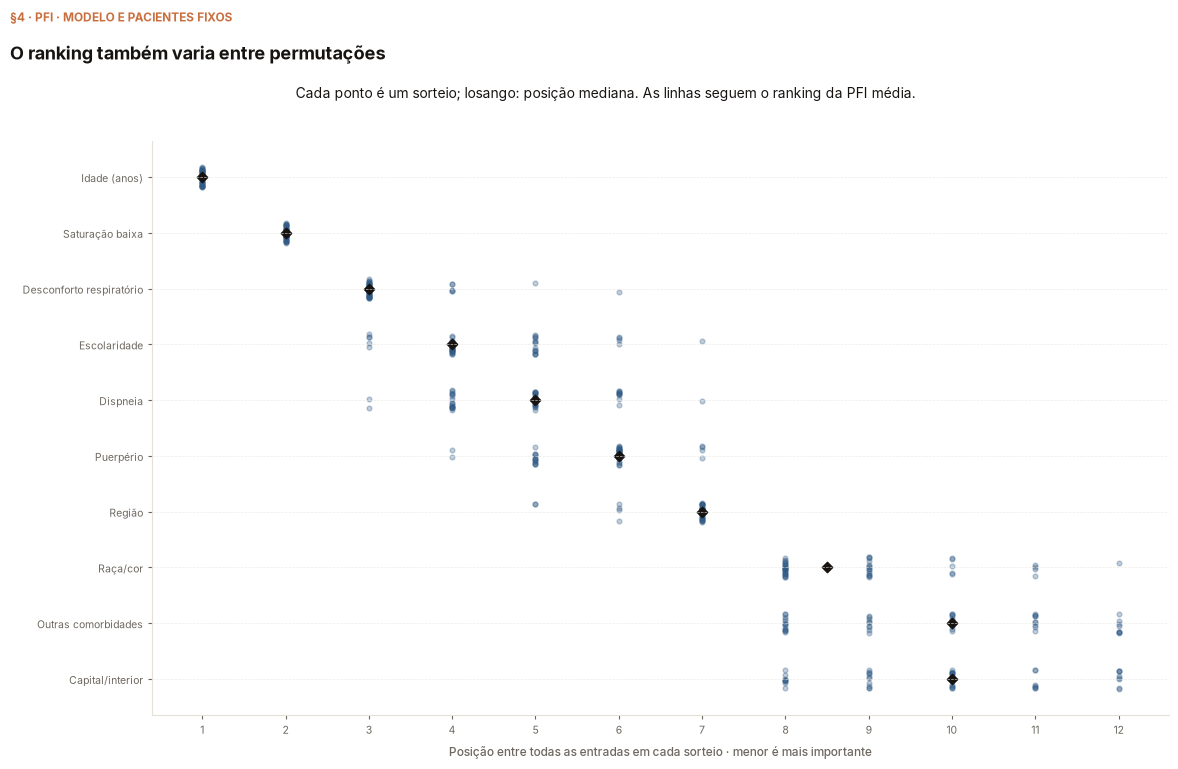

In [5]:
figures = P.figures(E, WORK / "figures_generated")
for figure in figures[:2]:
    display(figure)
    plt.close(figure)

**O que olhar.** A primeira figura permite ler o experimento inteiro; a ampliação
permite comparar diferenças menores sem confundir eixos de escalas diferentes.

## §4 — O ranking muda entre os sorteios?

Calculamos uma posição para cada entrada em cada repetição, considerando todas
as colunas. Empates recebem a posição média. O gráfico mantém as linhas ordenadas
pela PFI média; cada ponto horizontal é a posição obtida em uma repetição.
Presença entre as maiores descreve estabilidade nestes sorteios, sem medir a
probabilidade de uma posição se repetir em outra população.

        variável posição da PFI média posição mediana menor posição maior posição SD da posição fração nos dez primeiros
      idade_anos                    1        1,000000      1,000000      1,000000      0,000000                 1,000000
       saturacao                    2        2,000000      2,000000      2,000000      0,000000                 1,000000
       desc_resp                    3        3,000000      3,000000      6,000000      0,571429                 1,000000
      cs_escol_n                    4        4,000000      3,000000      7,000000      0,857143                 1,000000
        dispneia                    5        5,000000      3,000000      7,000000      0,873417                 1,000000
        puerpera                    6        6,000000      4,000000      7,000000      0,664247                 1,000000
          regiao                    7        7,000000      5,000000      7,000000      0,467734                 1,000000
         cs_raca                

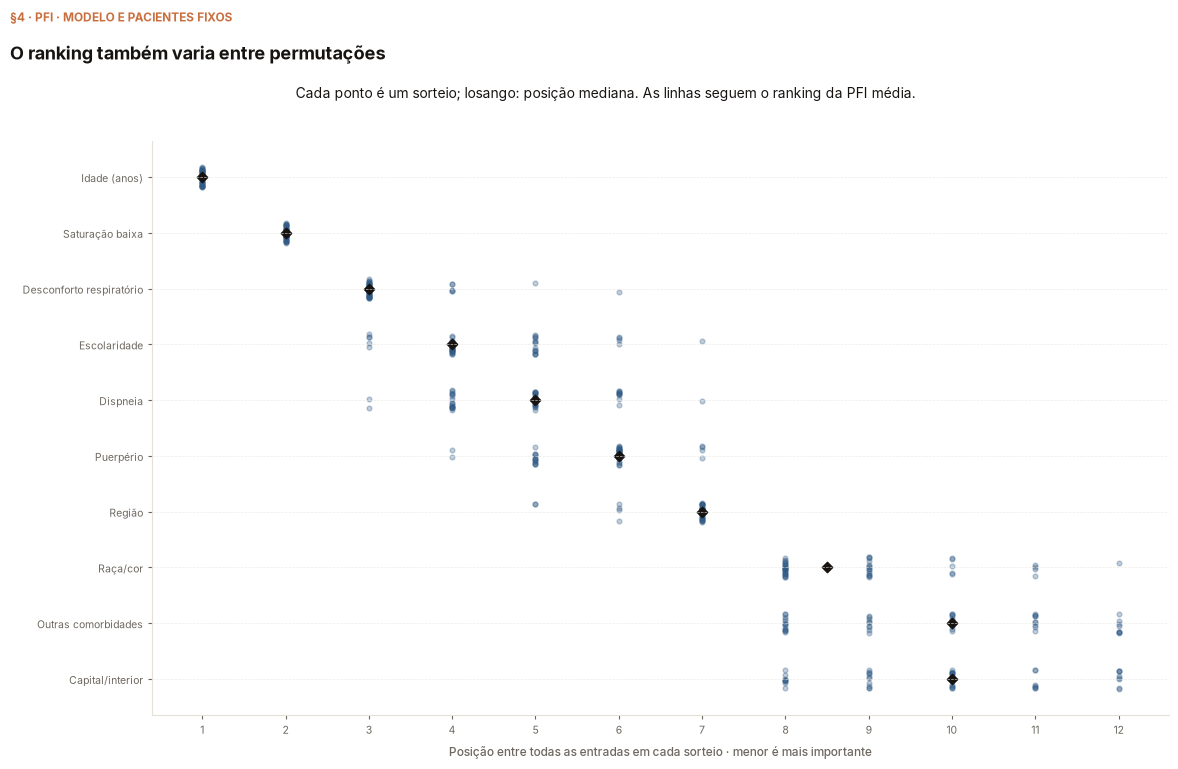

In [6]:
rank_table = pd.DataFrame([{
    "variável": r["feature"], "posição da PFI média": r["metrics"]["brier"]["rank"],
    "posição mediana": np.median(r["metrics"]["brier"]["rank_repeats"]),
    "menor posição": min(r["metrics"]["brier"]["rank_repeats"]),
    "maior posição": max(r["metrics"]["brier"]["rank_repeats"]),
    "SD da posição": r["metrics"]["brier"]["rank_sd"],
    "fração nos dez primeiros": r["metrics"]["brier"]["top10_fraction"],
} for r in rows[:10]])
print(SP.tabela(rank_table, casas=6))
display(figures[2]); plt.close(figures[2])

**O que olhar.** Uma ordem média não garante uma posição fixa em cada sorteio.
Trocas entre posições próximas não significam que o modelo foi retreinado.

## §5 — Conferir as contas e os limites

Recalculamos médias, SD e diferenças a partir dos valores individuais armazenados.
O efeito da permutação é marginal: romper uma coluna também pode romper relações
com outras entradas e produzir combinações raras ou incompatíveis com as regras
da ficha. Portanto a PFI não é uma medida causal ou de relevância clínica intrínseca.

In [7]:
max_mean_error = 0.0
max_sd_error = 0.0
for row in rows:
    for metric, summary in row["metrics"].items():
        after = np.asarray(summary["after"])
        delta = np.asarray(summary["delta"])
        direction = -1 if metric == "auc" else 1
        np.testing.assert_allclose(delta, direction * (after - E["original"][metric]), rtol=0, atol=1e-15)
        assert len(after) == protocol["repeats"]
        max_mean_error = max(max_mean_error, abs(delta.mean() - summary["mean"]))
        max_sd_error = max(max_sd_error, abs(delta.std(ddof=1) - summary["sd"]))
        assert np.isclose(after.std(ddof=1), delta.std(ddof=1))
print("Maior discrepância das médias:", SP.pt(max_mean_error, 12))
print("Maior discrepância dos SD:", SP.pt(max_sd_error, 12))
print("Colunas com previsões idênticas ao original em todos os sorteios:")
for row in rows:
    if row["identical_predictions"]:
        print(row["feature"], "PFI:", SP.pt(row["metrics"]["brier"]["mean"], 8))

Maior discrepância das médias: 0,000000000000
Maior discrepância dos SD: 0,000000000000
Colunas com previsões idênticas ao original em todos os sorteios:
meses_desde_mar2020 PFI: 0,00000000


## §6 — Síntese e vínculo com o livro

**O que o livro diz.** Molnar define a importância como a mudança de desempenho
de um modelo fixo quando uma entrada é permutada. A repetição descreve a variação
da perturbação; não incorpora, sozinha, incerteza de reamostrar pacientes,
retreinar o modelo ou transportá-lo para outro período.

Aqui “antes e depois” são erros do mesmo preditor. Não são importâncias internas
antes e depois de um novo treinamento. A importância interna por ganho usa outra
definição e outra escala, e não foi usada como a referência desta comparação.

In [8]:
winner=rows[0]; s=winner["metrics"]["brier"]
print("Maior PFI média de Brier:", winner["feature"])
print("Erro original:", SP.pt(E["original"]["brier"], 8))
print("Erro após permutar, média:", SP.pt(s["after_mean"], 8))
print("Aumento médio ± SD:", SP.pt(s["mean"], 8), "±", SP.pt(s["sd"], 8))
print("Intervalo de posições nos sorteios:", SP.pt(min(s["rank_repeats"]), 1), "a", SP.pt(max(s["rank_repeats"]), 1))
print("Leitura condicionada ao modelo atual, ao teste histórico e às permutações descritas.")

Maior PFI média de Brier: idade_anos
Erro original: 0,13080778
Erro após permutar, média: 0,15425722
Aumento médio ± SD: 0,02344944 ± 0,00073672
Intervalo de posições nos sorteios: 1,0 a 1,0
Leitura condicionada ao modelo atual, ao teste histórico e às permutações descritas.


Fontes: [Molnar — Permutation Feature Importance](https://christophm.github.io/interpretable-ml-book/feature-importance.html) ·
[scikit-learn — permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).